In [ ]:
%pip install scikit-learn pandas pyarrow matplotlib -r ../../../agdata/requirements.txt

# Six-month forecasts of five farm-weather variables (gradient boosting)

**Goal:** from the start of each month, forecast the **monthly mean** of five NASA POWER variables for the
next 6 months:

| Code | Variable |
|---|---|
| `T2M` | Air temperature at 2 m (°C) |
| `PRECTOTCORR` | Precipitation (mm/day) |
| `ALLSKY_SFC_SW_DWN` | Solar radiation at the surface (MJ/m²/day) |
| `RH2M` | Relative humidity at 2 m (%) |
| `GWETROOT` | Root zone soil wetness (0 = dry … 1 = saturated) |

We predict monthly means rather than daily values because day-to-day weather can't be predicted six months
ahead. Any skill shows up in monthly anomalies, meaning how far a month lands above or below its usual value.

**Data (all through `agdata`, no credentials needed):**
- **NASA POWER**, monthly (`ag.NasaPower.area`): history and targets on a ~50 km grid (MERRA-2 for
  weather, CERES for solar radiation). Surface and full-profile soil wetness (`GWETTOP`, `GWETPROF`) are
  extra inputs.
- **NASA GMAO GEOS-S2S** seasonal forecasts (`ag.NMME`, via NOAA CPC): the physics model's forecast
  anomalies of precipitation and 2 m temperature for each target month. They exist from 2018-04. Older
  rows have them missing, which gradient boosting handles natively.

**Model:** scikit-learn `HistGradientBoostingRegressor`. Each variable gets 3 models (10th, 50th and 90th
percentile), so every forecast comes with an 80% range. Each model is trained on **all ~108 grid cells**
of a region around the field. A single cell has only ~20 years of history, which is too few seasons to
learn from.

## Data split (chronological)

| Set | Forecasts | Used for |
|---|---|---|
| Train | target months before 2025-03 (origins from 2006-04) | fitting |
| Validation | the 12 origins 2025-03-01 … 2026-02-01 | reporting skill before the test |
| Test | origin **2026-03-01**, targets Mar–Aug 2026 | final check, once |

The model is refit on all data before 2026-03 to make the test forecast. Monthly climatology (the "normal"
each anomaly is measured against) uses only data before each set's start. The hyperparameters below were
chosen in a separate 5-fold yearly backtest (2021–2025), which overlaps the validation year. That makes the
validation scores slightly optimistic. The test season was not used for any choice.

In [1]:
import sys
import time
from pathlib import Path

import aiohttp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor

REPO = Path.cwd().parents[2]  # This notebook lives in Model/regressions/exploration/.
assert (REPO / 'agdata').is_dir(), f'agdata not found under {REPO}'
sys.path.insert(0, str(REPO))
import agdata as ag

## Parameters

In [2]:
# The 20 km² field from the LSTM notebook, and the region pooled for training (~108 POWER cells, Iowa).
CENTER_LAT, CENTER_LON = 42.00, -93.60
BBOX = (-97.0, 40.0, -90.0, 44.0)  # (west, south, east, north); POWER regions span at most 10°

# Data split.
START = pd.Timestamp('2006-01-01')       # 20 years of history before the test
VAL_START = pd.Timestamp('2025-03-01')
TEST_START = pd.Timestamp('2026-03-01')  # forecast origin of the test
LEADS = range(1, 7)                      # lead 1 = the month starting at the origin; 6 months in total

TARGETS = {
    'T2M': 'Air temperature (°C)',
    'PRECTOTCORR': 'Precipitation (mm/day)',
    'ALLSKY_SFC_SW_DWN': 'Solar radiation (MJ/m²/day)',
    'RH2M': 'Relative humidity (%)',
    'GWETROOT': 'Root zone soil wetness (0–1)',
}
EXTRA = ['GWETTOP', 'GWETPROF']  # inputs only: surface and full-profile soil wetness
VARIABLES = [*TARGETS, *EXTRA]

# Gradient boosting. Neighbouring cells move together, so the data hold ~230 independent months, not
# ~150k rows. Small trees with large leaves (>= 5000 rows, i.e. many months) stop the model from
# memorising single years; looser settings scored worse in the backtest on every variable.
HGB_PARAMS = dict(max_iter=60, learning_rate=0.05, max_leaf_nodes=4, min_samples_leaf=5000,
                  l2_regularization=1.0, early_stopping=False, random_state=0)
QUANTILES = (0.1, 0.5, 0.9)  # 80% range + median

# Downloads are cached; delete this folder after changing BBOX or dates.
CACHE = Path('cache')

## 1. Fetch data

NASA POWER takes seconds. The GEOS-S2S forecasts take about 4 minutes the first time: two 2.2 MB files per
issue month. Both are then cached as Parquet.

In [3]:
CACHE.mkdir(exist_ok=True)
power_file, geos_file = CACHE / 'power_monthly.parquet', CACHE / 'geos_s2s.parquet'
async with aiohttp.ClientSession() as http:
    if not power_file.exists():
        frame = await ag.NasaPower(http).area(
            BBOX, START, TEST_START + pd.DateOffset(months=6) - pd.Timedelta(days=1),
            parameters=VARIABLES, resolution='monthly')
        print('POWER units:', frame.attrs)
        frame = frame[~frame.time.str.endswith('13')]  # month 13 is the annual mean
        frame.assign(time=pd.to_datetime(frame.time, format='%Y%m')).to_parquet(power_file)
    if not geos_file.exists():
        # Forecasts issued up to the month before the test origin: the 2026-03 issue comes out ~March 8.
        frame = await ag.NMME(http).area(BBOX, '2018-01-01', TEST_START - pd.DateOffset(months=1))
        print('Months without a GEOS-S2S forecast:', frame.attrs['missing'], 'units:', frame.attrs)
        frame.to_parquet(geos_file)

power = pd.read_parquet(power_file)
geos = pd.read_parquet(geos_file)
print(f'POWER: {len(power)} rows; GEOS-S2S: {geos.issued.nunique()} issue months')

POWER units: {'T2M': 'C', 'PRECTOTCORR': 'mm/day', 'ALLSKY_SFC_SW_DWN': 'MJ/m^2/day', 'RH2M': '%', 'GWETROOT': '1', 'GWETTOP': '1', 'GWETPROF': '1'}


Months without a GEOS-S2S forecast: ['2018-01', '2018-02', '2018-03', '2025-04'] units: {'prate': 'mm/s', 'tmp2m': 'K', 'missing': ['2018-01', '2018-02', '2018-03', '2025-04']}
POWER: 32820 rows; GEOS-S2S: 94 issue months


POWER serves solar radiation on CERES's 1° grid (centres at x.5°), and the other variables on MERRA-2's
0.5° × 0.625° grid. So each MERRA-2 cell takes the radiation of the 1° cell it falls in. Radiation is also
published with a delay, so its most recent months are missing.

In [4]:
radiation = power.dropna(subset=['ALLSKY_SFC_SW_DWN'])[['time', 'lat', 'lon', 'ALLSKY_SFC_SW_DWN']]
power = power.dropna(subset=['T2M']).drop(columns='ALLSKY_SFC_SW_DWN')
power['rlat'] = (np.floor(power.lat) + 0.5).clip(radiation.lat.min(), radiation.lat.max())
power['rlon'] = (np.floor(power.lon) + 0.5).clip(radiation.lon.min(), radiation.lon.max())
power = power.merge(radiation.rename(columns={'lat': 'rlat', 'lon': 'rlon'}),
                    on=['time', 'rlat', 'rlon'], how='left').drop(columns=['rlat', 'rlon'])

# Validate the external data before use.
assert power.drop(columns='ALLSKY_SFC_SW_DWN').notna().all().all(), 'POWER gaps outside radiation'
assert power.GWETROOT.between(0, 1).all() and power.RH2M.between(0, 100).all()
assert (power.PRECTOTCORR >= 0).all() and (power.ALLSKY_SFC_SW_DWN.dropna() >= 0).all()
print('Last radiation month:', power.dropna(subset=['ALLSKY_SFC_SW_DWN']).time.max().date())

cells = power[['lat', 'lon']].drop_duplicates()
center = cells.iloc[((cells.lat - CENTER_LAT) ** 2 + (cells.lon - CENTER_LON) ** 2).argmin()]
print(f'{len(cells)} cells; the field is in cell ({center.lat}, {center.lon})')

# GEOS-S2S forecasts usable at the start of month M were issued in month M-1.
geos_features = pd.DataFrame({
    'glat': geos.lat, 'glon': geos.lon,
    'origin': geos.issued + pd.DateOffset(months=1), 'target': geos.target,
    'geos_prate': geos.prate * 86400,  # mm/s -> mm/day
    'geos_tmp2m': geos.tmp2m,
})

Last radiation month: 2026-07-01
108 cells; the field is in cell (42.0, -93.75)


## 2. Look at the data: seasonal cycle at the field

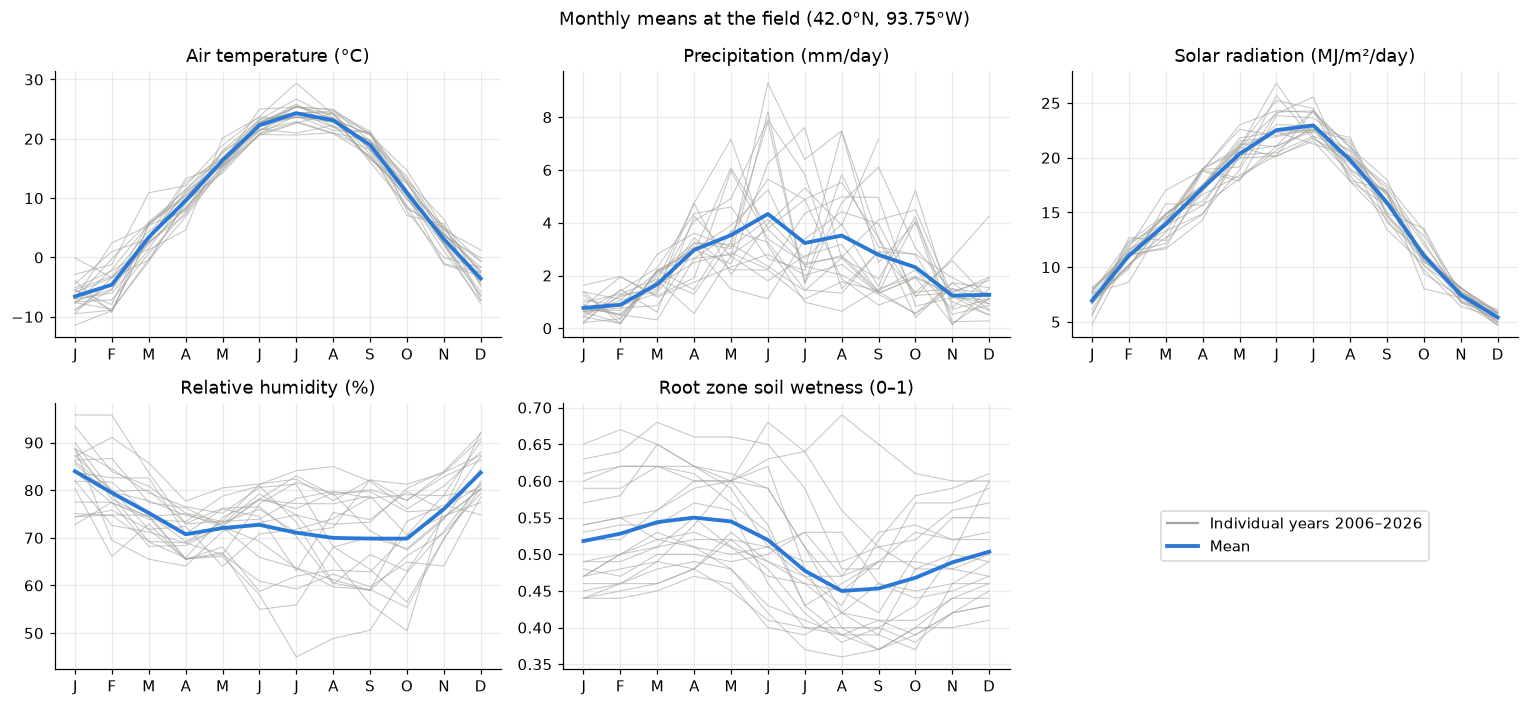

In [5]:
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.alpha': 0.25, 'figure.dpi': 110})
OBSERVED, FORECAST, MUTED = '#2a78d6', '#eb6834', '#a3a29c'

at_field = power[(power.lat == center.lat) & (power.lon == center.lon)].set_index('time')
fig, axes = plt.subplots(2, 3, figsize=(14, 6.5))
for ax, (code, label) in zip(axes.flat, TARGETS.items()):
    series = at_field[code].dropna()
    for _, year in series.groupby(series.index.year):
        ax.plot(year.index.month, year.to_numpy(), color=MUTED, lw=0.7, alpha=0.6)
    ax.plot(series.groupby(series.index.month).mean(), color=OBSERVED, lw=2.5)
    ax.set(title=label, xticks=range(1, 13), xticklabels=list('JFMAMJJASOND'))
axes.flat[-1].axis('off')
axes.flat[-1].legend(handles=[plt.Line2D([], [], color=MUTED, label='Individual years 2006–2026'),
                              plt.Line2D([], [], color=OBSERVED, lw=2.5, label='Mean')], loc='center')
fig.suptitle(f'Monthly means at the field ({center.lat}°N, {-center.lon}°W)')
fig.tight_layout()
plt.show()

**Pattern:** temperature and solar radiation follow a strong, regular seasonal cycle with little spread
between years, so the seasonal average already explains almost all of their variation. Precipitation
peaks in May–June and is very noisy from year to year. Humidity is lowest in spring. Root zone soil
wetness peaks in spring and dries through late summer, with very wide year-to-year spread. It also changes
slowly, which is why it is the most predictable of the five.

## 3. Features

Every forecast row is (grid cell, origin month, lead). All inputs are known at the origin:

| Feature | Meaning |
|---|---|
| `<var>_last1`, `<var>_last3` | anomaly of each of the 7 variables over the last 1 and 3 months |
| `geos_prate`, `geos_tmp2m` | GEOS-S2S forecast anomaly for the target month (missing before 2018-04 and for 2025-04) |
| `clim_<target>` | the cell's normal value for the target month |
| `lead`, `target_month`, `lat`, `lon` | how far ahead, which calendar month, where |

The model predicts the **anomaly** of the target month; the forecast is normal value + predicted anomaly.

In [6]:
def build(clim_end: pd.Timestamp) -> pd.DataFrame:
    """Returns one row per cell, origin and lead; anomalies use the climatology before `clim_end`."""
    panel = power.assign(month=power.time.dt.month)
    clim = panel[panel.time < clim_end].groupby(['lat', 'lon', 'month'])[VARIABLES].mean()
    normal = clim.reindex(pd.MultiIndex.from_frame(panel[['lat', 'lon', 'month']])).to_numpy()
    anomaly = pd.concat([panel[['lat', 'lon', 'time']],
                         pd.DataFrame(panel[VARIABLES].to_numpy() - normal, columns=VARIABLES)], axis=1)
    anomaly = anomaly.set_index(['lat', 'lon', 'time']).sort_index()

    by_cell = anomaly.groupby(level=['lat', 'lon'])
    known = pd.concat([  # Known at the start of each month.
        by_cell.shift(1).add_suffix('_last1'),
        by_cell.transform(lambda s: s.rolling(3).mean().shift(1)).add_suffix('_last3'),
    ], axis=1).reset_index().rename(columns={'time': 'origin'})
    rows = pd.concat([known.assign(lead=lead, target=known.origin + pd.DateOffset(months=lead - 1))
                      for lead in LEADS], ignore_index=True)
    rows['target_month'] = rows.target.dt.month
    rows = rows.merge(anomaly[list(TARGETS)].add_prefix('y_').reset_index()
                      .rename(columns={'time': 'target'}), on=['lat', 'lon', 'target'])
    rows = rows.merge(clim[list(TARGETS)].add_prefix('clim_').reset_index()
                      .rename(columns={'month': 'target_month'}), on=['lat', 'lon', 'target_month'])
    rows['glat'], rows['glon'] = np.floor(rows.lat + 0.5), np.floor(rows.lon + 0.5)  # nearest 1° node
    rows = rows.merge(geos_features, on=['glat', 'glon', 'origin', 'target'], how='left')
    return rows.drop(columns=['glat', 'glon']).dropna(subset=['T2M_last3'])


def fit_predict(rows: pd.DataFrame, train: pd.Series, test: pd.Series) -> dict:
    """Fits one model per target and quantile; returns {(target, quantile): predicted anomalies}."""
    predictions = {}
    for code in TARGETS:
        fit_rows = rows[train & rows[f'y_{code}'].notna()]
        for q in QUANTILES:
            model = HistGradientBoostingRegressor(loss='quantile', quantile=q, **HGB_PARAMS)
            model.fit(fit_rows[FEATURES], fit_rows[f'y_{code}'])
            predictions[code, q] = model.predict(rows.loc[test, FEATURES])
    return predictions


def score(rows: pd.DataFrame, predictions: dict) -> pd.DataFrame:
    """Per target: errors of the median forecast, of the normal value and of persistence."""
    table = {}
    for code, label in TARGETS.items():
        observed = rows[f'y_{code}'].to_numpy()
        ok = ~np.isnan(observed)
        y, low, mid, high = (a[ok] for a in (observed, *(predictions[code, q] for q in QUANTILES)))
        mae, mae_normal = np.abs(y - mid).mean(), np.abs(y).mean()
        mae_persistence = np.abs(y - rows[f'{code}_last1'].to_numpy()[ok]).mean()
        table[label] = {
            'MAE': mae, 'MAE normal': mae_normal,
            'skill vs normal': 1 - mae / mae_normal,
            'skill of persistence': 1 - mae_persistence / mae_normal,
            '80% range coverage': np.mean((y >= low) & (y <= high)),
            'forecasts per cell': ok.sum() // len(rows[['lat', 'lon']].drop_duplicates()),
        }
    return pd.DataFrame(table).T


started = time.perf_counter()
rows_val = build(VAL_START)
FEATURES = [c for c in rows_val.columns if c not in ('origin', 'target') and not c.startswith('y_')]
print(f'{len(rows_val)} rows, {len(FEATURES)} features, built in {time.perf_counter() - started:.1f} s')

157788 rows, 25 features, built in 0.4 s


## 4. Validation: 12 origins, 2025-03 … 2026-02

In [7]:
is_train = rows_val.target < VAL_START
is_val = (rows_val.origin >= VAL_START) & (rows_val.origin < TEST_START)
started = time.perf_counter()
val_predictions = fit_predict(rows_val, is_train, is_val)
print(f'Trained {len(TARGETS) * len(QUANTILES)} models in {time.perf_counter() - started:.1f} s '
      f'on {is_train.sum()} rows')
score(rows_val[is_val], val_predictions).round(3)

Trained 15 models in 11.9 s on 145476 rows


,MAE,MAE normal,skill vs normal,skill of persistence,80% range coverage,forecasts per cell
Air temperature (°C),1.473,1.619,0.090,-0.133,0.786,72.0
Precipitation (mm/day),0.991,1.008,0.017,-0.472,0.804,72.0
Solar radiation (MJ/m²/day),0.667,0.649,-0.027,-0.472,0.965,72.0
Relative humidity (%),5.138,5.204,0.013,-0.299,0.731,72.0
Root zone soil wetness (0–1),0.039,0.054,0.266,0.180,0.734,72.0


## 5. Test: forecast from 2026-03-01

In [8]:
rows = build(TEST_START)
is_test = rows.origin == TEST_START
started = time.perf_counter()
test_predictions = fit_predict(rows, rows.target < TEST_START, is_test)
print(f'Refit in {time.perf_counter() - started:.1f} s')
test_rows = rows[is_test].reset_index(drop=True)
score(test_rows, test_predictions).round(3)

Refit in 10.0 s


,MAE,MAE normal,skill vs normal,skill of persistence,80% range coverage,forecasts per cell
Air temperature (°C),1.049,1.400,0.250,-1.260,0.858,6.0
Precipitation (mm/day),1.155,1.102,-0.048,-0.163,0.776,6.0
Solar radiation (MJ/m²/day),0.895,0.877,-0.020,-0.132,0.891,5.0
Relative humidity (%),3.830,4.149,0.077,-0.088,0.917,6.0
Root zone soil wetness (0–1),0.025,0.048,0.480,0.259,0.894,6.0


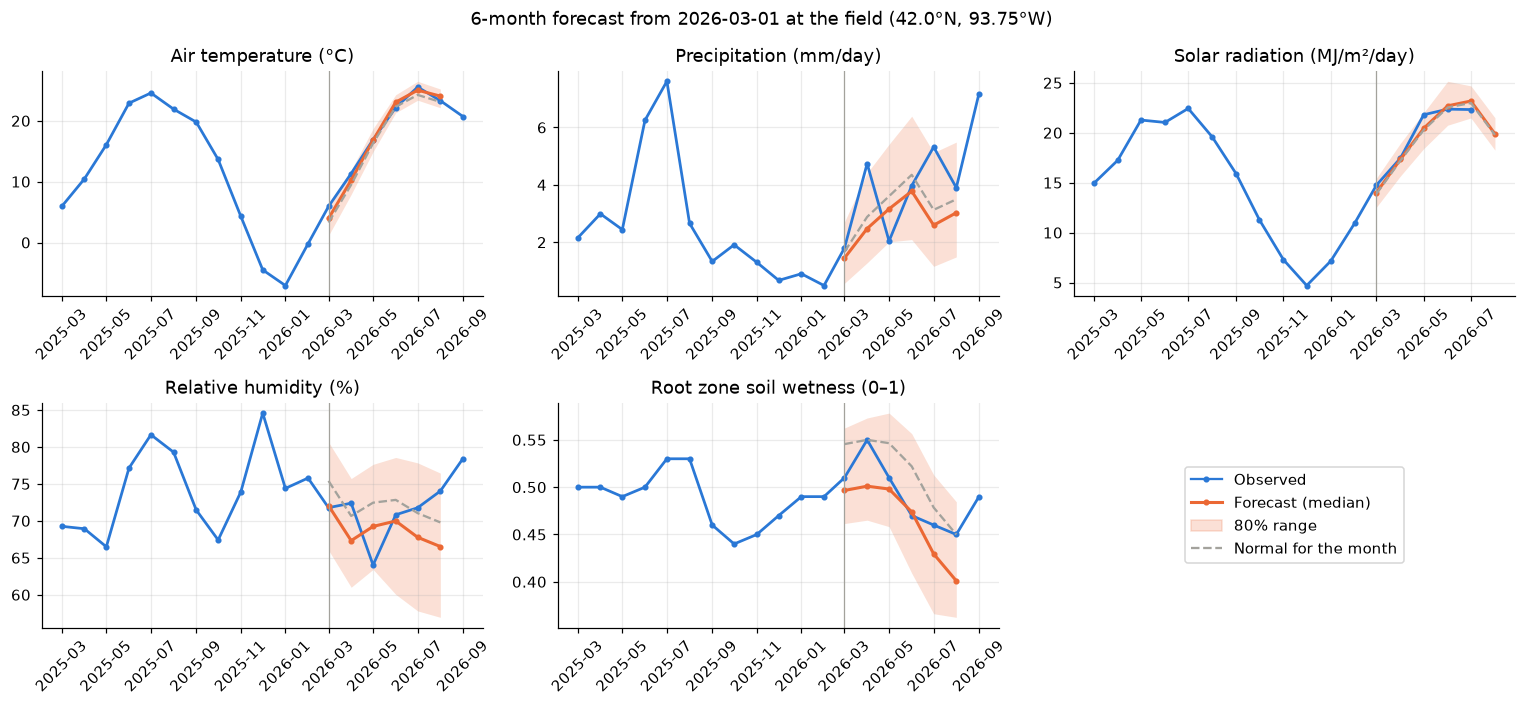

In [9]:
at_center = ((test_rows.lat == center.lat) & (test_rows.lon == center.lon)).to_numpy()
months = test_rows.target[at_center]
fig, axes = plt.subplots(2, 3, figsize=(14, 6.5))
for ax, (code, label) in zip(axes.flat, TARGETS.items()):
    normal = test_rows[f'clim_{code}'][at_center].to_numpy()
    low, mid, high = (normal + test_predictions[code, q][at_center] for q in QUANTILES)
    history = at_field[code].loc[TEST_START - pd.DateOffset(months=12):].dropna()
    ax.plot(history, color=OBSERVED, lw=1.8, marker='o', ms=3)
    ax.fill_between(months, low, high, color=FORECAST, alpha=0.2, lw=0)
    ax.plot(months, mid, color=FORECAST, lw=2, marker='o', ms=3)
    ax.plot(months, normal, color=MUTED, lw=1.5, ls='--')
    ax.axvline(TEST_START, color=MUTED, lw=0.8)
    ax.set_title(label)
    ax.tick_params(axis='x', labelrotation=45)
axes.flat[-1].axis('off')
axes.flat[-1].legend(handles=[
    plt.Line2D([], [], color=OBSERVED, marker='o', ms=3, label='Observed'),
    plt.Line2D([], [], color=FORECAST, lw=2, marker='o', ms=3, label='Forecast (median)'),
    plt.Rectangle((0, 0), 1, 1, color=FORECAST, alpha=0.2, label='80% range'),
    plt.Line2D([], [], color=MUTED, ls='--', label='Normal for the month')], loc='center')
fig.suptitle(f'6-month forecast from {TEST_START.date()} at the field ({center.lat}°N, {-center.lon}°W)')
fig.tight_layout()
plt.show()

## Notes

- **How to read the scores.** *Skill vs normal* = 1 − MAE(forecast) / MAE(normal value for the month).
  0 means no better than the normal value, and 1 is perfect. It replaces the earlier "1 − MAPE accuracy",
  which breaks for precipitation (months near 0 mm) and for temperature (crosses 0 °C). *80% range
  coverage* should be close to 0.8.
- **What is predictable six months out:** root zone soil wetness clearly is, because soil remembers past
  rain. Humidity and temperature are only slightly predictable, and temperature is where GEOS-S2S helps
  most. Precipitation and solar radiation are barely predictable beyond the normal value, which matches
  published seasonal-forecast skill for the US Midwest.
- **One test season is one sample;** the 2021–2025 backtest (5 seasons) is the firmer estimate.
- **Weak hardware:** all 15 models train in seconds. The slow part is the first GEOS-S2S download. Shrink
  `BBOX` (fewer cells) if memory is tight.
- **Next steps:** add the NMME multi-model mean (`ag.NMME(http).area(..., model='NMME')`) as a second
  forecast source, and add soil type (`ag.SSURGO`) as a per-cell feature.